In [17]:
from typing import TypedDict , Annotated
from langgraph.graph import StateGraph, START, END ,MessagesState
import wikipediaapi
from dotenv import load_dotenv
from langchain.chat_models import init_chat_model
from langgraph.graph.message import add_messages
import operator
from openai import OpenAI
import os
from langchain_openai import ChatOpenAI
from langchain_core.tools import tool 
from langgraph.prebuilt import ToolNode,tools_condition
from langchain_core.messages import ToolMessage
from IPython.display import Image, display


load_dotenv()
llm = ChatOpenAI(
    model="openai/gpt-oss-20b",
    api_key=os.environ.get("GROQ_API_KEY"),
    base_url="https://api.groq.com/openai/v1",
)


Part 1: Researcher Graph


In [20]:
wiki = wikipediaapi.Wikipedia(user_agent="3 agents_project/1.0 (student@example.com)")
MAX_CHARS_PER_PAGE = 3000

@tool 
def wiki_search(query: str)-> str:
    """Search Wikipedia for a query and return raw text from the top matching pages."""
    results = wiki.search(query, limit=3)
    output = ""
    for title, page in results.pages.items():
        output += f" {title}\n{page.text[:MAX_CHARS_PER_PAGE]}\n\n"
    return output or f"No results found for: {query}"

tools = [wiki_search]
llm_with_tools = llm.bind_tools(tools)


ResearcherState=TypedDict("ResearcherState",{"task":str,"research":str,"messages": Annotated[list, add_messages], "trace": Annotated[list, operator.add]})

def researcher_node(state: ResearcherState) -> dict:
    response = llm_with_tools.invoke([("system", "You are a research agent. You must call the Wikipedia tool to gather information about the task. Do not summarize, rewrite, or format anything. Return raw notes only"), 
                                    ("human", state["task"])] + state["messages"])
    tool_texts = [m.content for m in state["messages"] if isinstance(m, ToolMessage)] 
    if tool_texts:
        research = "\n\n".join(tool_texts)
    else:
        research = state["research"]
    return {"research": research, "messages": [response], "trace": ["researcher"]}

builder = StateGraph(ResearcherState)
builder.add_node("researcher_node", researcher_node)
builder.add_node("research_tools", ToolNode(tools))

builder.add_edge(START,"researcher_node")
builder.add_conditional_edges("researcher_node",tools_condition,{"tools":"research_tools",END:END},)
builder.add_edge("research_tools", "researcher_node")

researcher_app = builder.compile()



Task 5: Run the Researcher Standalone

In [22]:
result = researcher_app.invoke({
    "task": "Research the history of the Python programming language.",
    "research": "",
    "messages": [],
    "trace": [],
})

print("TRACE:", result["trace"])
print("RESEARCH LENGTH:", len(result["research"]))
print("RESEARCH PREVIEW:", result["research"][:500])
print("MESSAGE TYPES:", [type(m).__name__ for m in result["messages"]])

TRACE: ['researcher', 'researcher']
RESEARCH LENGTH: 9100
RESEARCH PREVIEW:  Python (programming language)
Python is a high-level, general-purpose programming language that emphasizes code readability, simplicity, and ease-of-writing with the use of significant indentation, an extensive ("batteries-included") standard library, and garbage collection. Python supports multiple programming paradigms but with an emphasis on object-oriented programming and dynamic typing.
Guido van Rossum began working on Python in the late 1980s as a successor to the ABC programming languag
MESSAGE TYPES: ['AIMessage', 'ToolMessage', 'AIMessage']


Task 6: Visualize the Researcher Graph

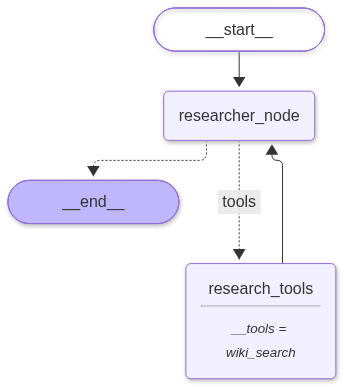

In [18]:
display(Image(researcher_app.get_graph().draw_mermaid_png()))

Part 2: Build the Writer Graph

In [25]:
writerState=TypedDict("writerState",{"task":str,"research":str,"feedback":str,"draft":str,"attempts":int,"messages": Annotated[list, add_messages], "trace": Annotated[list, operator.add]})

def writer_node(state: writerState) -> dict:
    prompt = f"Task: {state['task']}"

    if state["research"]:
        prompt += f"\n\nResearch:\n{state['research']}"

    if state["feedback"]:
        prompt += f"\n\nFeedback:\n{state['feedback']}"

    response = llm.invoke([("system", "You are a writing agent. You must write a draft based on the task, research, and feedback. Do not summarize, rewrite, or format anything. Return raw notes only"),        
                           ("human", prompt)] + state["messages"])

    return {"draft": response.content, "messages": [response], "trace": ["writer"]}   


builder = StateGraph(writerState)
builder.add_node("writer_node", writer_node)
builder.add_edge(START,"writer_node")
builder.add_edge("writer_node", END)
writer_app = builder.compile()


Task 4: Run the Writer Standalone

In [31]:
result = writer_app.invoke({
    "task": "Write a 3-sentence pitch for a plant-watering mobile app.",
    "research": "",
    "feedback": "",
    "draft": "",
    "attempts": 0,
    "messages": [],
    "trace": []
})

print("draft:",result["draft"])
print("TRACE:", result["trace"])
print("feedback:",result["feedback"])

draft: Tired of wilting succulents because you forget to water them? Our app learns your plants' needs and sends timely reminders, even predicting when to water based on weather and soil sensors. Stay green, stress‑free, and watch your indoor jungle thrive with minimal effort.
TRACE: ['writer']
feedback: 


Task 5: Visualize the Writer Graph

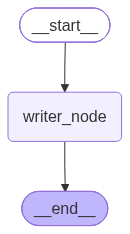

In [27]:
display(Image(writer_app.get_graph().draw_mermaid_png()))

Part 3: Build the Reviewer Graph

In [39]:
from pydantic import BaseModel, Field
from langchain_core.messages import AIMessage
class Review(BaseModel):
    feedback: str = Field(description="Specific, actionable feedback on the draft.")
    approved: bool = Field(description="True if the draft is good enough to publish.")

reviewerState=TypedDict("reviewerState",{"task":str,"feedback":str,"draft":str,"approved":bool,"messages": Annotated[list, add_messages], "trace": Annotated[list, operator.add]})
structured_model= llm.with_structured_output(Review)

def reviewer_node(state: reviewerState) -> dict:
    prompt = ([("system", "You are a strict reviewer. Judge the draft against the task and its constraints. Give specific, actionable feedback. Set approved to true only if the draft fully meets the task; otherwise set it to false."),        
              ("human", f"Task: {state['task']}\n\nDraft:\n{state['draft']}")])
    review = structured_model.invoke(prompt)
    return {"feedback": review.feedback, "approved": review.approved, "messages": [AIMessage(content=review.feedback)] , "trace": ["reviewer"]}

state_graph = StateGraph(reviewerState)
state_graph.add_node("reviewer_node", reviewer_node)

state_graph.add_edge(START,"reviewer_node")
state_graph.add_edge("reviewer_node", END)

reviewer_app = state_graph.compile()


Task 5: Run the Reviewer Standalone


In [40]:
result = reviewer_app.invoke({"task": "Write a slogan for a coffee shop.",
"draft": "Coffee that wakes you up and keeps you going.",
"feedback": "", "approved": False, "messages": [], "trace": []})
print (result)

{'task': 'Write a slogan for a coffee shop.', 'feedback': 'The slogan is a bit long and could be more punchy. Consider condensing it to a shorter, memorable phrase that captures the brand’s spirit, such as "Wake Up. Stay Strong."', 'draft': 'Coffee that wakes you up and keeps you going.', 'approved': False, 'messages': [AIMessage(content='The slogan is a bit long and could be more punchy. Consider condensing it to a shorter, memorable phrase that captures the brand’s spirit, such as "Wake Up. Stay Strong."', additional_kwargs={}, response_metadata={}, id='be51f0ec-5402-429c-ac36-5309625c4a4a', tool_calls=[], invalid_tool_calls=[])], 'trace': ['reviewer']}


Task 6: Visualize the Reviewer Graph

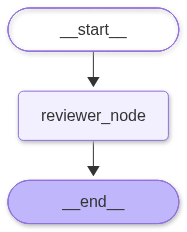

In [41]:
display(Image(reviewer_app.get_graph().draw_mermaid_png()))

Part 4: Build the Orchestration Layer